# 10 · Closed edges instead of a wrap-around grid

All notebooks so far use **periodic** boundaries, as the originals did: a tumour leaving the right edge reappears on the left, as if the tissue were a doughnut. A patch of tissue is better described by **no-flux** (closed) edges, where nothing crosses the boundary.

This notebook runs two models both ways using the shared `laplacian(..., bc=...)`:
- model 4 (diffusion + proliferation);
- the extension model 06 (vessels set the carrying capacity), to see whether its result depends on the edges.

In [1]:
import sys
sys.path.insert(0, "..")    # shared code lives in corrected/angiogenesis.py
import numpy as np
import matplotlib.pyplot as plt
import angiogenesis as ag

In [2]:
l = 200
delta_t = 0.1
delta_x = 1
n_initial = ag.three_regions(l, cutoff=1e-3)
steps_to_show = [300, 600, 1000]

# ---- model 4 with both kinds of edges
frames, edge_rows = {}, {}
for bc in ("periodic", "noflux"):
    n = n_initial.copy()
    for step in range(1, 1001):
        n = ag.fk_step(n, D=0.05, alpha=1, n_max=1, dt=delta_t, dx=delta_x, bc=bc)
        if step in steps_to_show:
            frames[bc, step] = n.copy()
            edge_rows[bc, step] = (n.sum(), n[:, 0].sum())
    for step in steps_to_show:
        total, left_edge = edge_rows[bc, step]
        print(f"model 4, {bc:8s} step {step:4d}: total tumour {total:8.0f}   on the left edge {left_edge:6.1f}")

model 4, periodic step  300: total tumour    21395   on the left edge   34.3
model 4, periodic step  600: total tumour    30256   on the left edge  107.5
model 4, periodic step 1000: total tumour    37373   on the left edge  167.5


model 4, noflux   step  300: total tumour    21329   on the left edge    0.0
model 4, noflux   step  600: total tumour    28913   on the left edge    0.0
model 4, noflux   step 1000: total tumour    36378   on the left edge   63.7


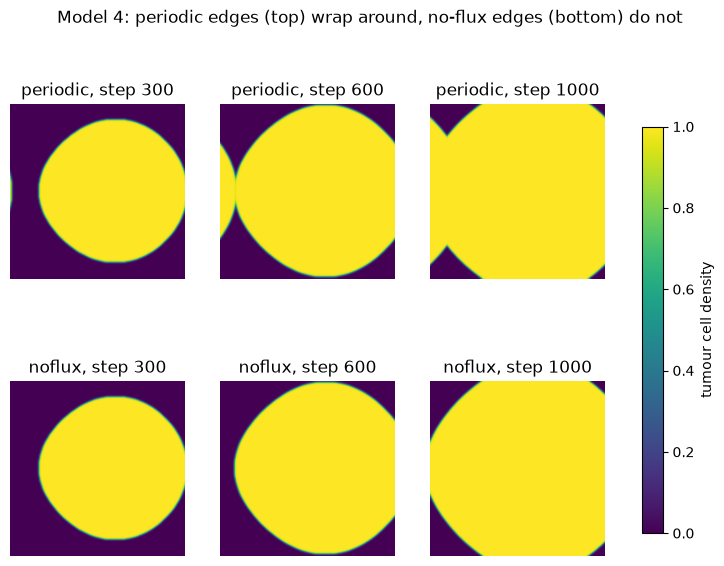

In [3]:
fig, axes = plt.subplots(2, len(steps_to_show), figsize=(3.2 * len(steps_to_show), 6.6))
for row, bc in enumerate(("periodic", "noflux")):
    for col, step in enumerate(steps_to_show):
        im = axes[row, col].imshow(frames[bc, step], origin="lower", cmap="viridis", vmin=0, vmax=1)
        axes[row, col].set_title(f"{bc}, step {step}")
for ax in axes.flat:
    ax.axis("off")
fig.colorbar(im, ax=axes, shrink=0.8, label="tumour cell density")
fig.suptitle("Model 4: periodic edges (top) wrap around, no-flux edges (bottom) do not")
plt.show()

In [4]:
# ---- extension model 06 with both kinds of edges
D_c, L = 40, 8
lam = D_c / L**2
s = 0.1 * lam
beta = ag.beta_split(l, 0.0, 0.5)
for bc in ("periodic", "noflux"):
    n, c, V = n_initial.copy(), np.ones((l, l)), np.ones((l, l))
    for step in range(1, 1001):
        n, c, V = ag.nutrient_step(n, c, V, beta, 0.2, 1, 1, 4, D_c, lam, s, delta_t, 20, delta_x, bc)
    print(f"model 06, {bc:8s}: mean tumour density, angiogenesis blocked (left) "
          f"{n[60:140, 20:80].mean():.3f}, active (right) {n[60:140, 120:180].mean():.3f}")

model 06, periodic: mean tumour density, angiogenesis blocked (left) 0.275, active (right) 0.455


model 06, noflux  : mean tumour density, angiogenesis blocked (left) 0.273, active (right) 0.455


**Reading the result.**

- **Model 4.** With periodic edges, tumour that leaves the right side re-enters on the left: the left edge already holds tumour cells at step 300. With no-flux edges, the left edge stays empty until the tumour itself reaches it, near step 1000. The total amount of tumour differs by at most about 4 %, so the wrap-around changes the picture more than the totals.
- **Model 06.** The result does not depend on the edges: the mean density is 0.27 where angiogenesis is blocked and 0.455 where it is active, either way.
- **How to switch.** The corrected notebooks keep periodic edges so they stay comparable with the originals. Passing `bc="noflux"` to the shared functions switches any model to closed edges.